In [29]:
import numpy as np
import pandas as pd
import airfrans as af
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

In [2]:
PATH_TO_SAVING_DIRECTORY = "./data"
PATH_TO_DATASET = "./data/Dataset"
TASK = "full"

In [5]:
 # af.dataset.download(root = PATH_TO_SAVING_DIRECTORY, unzip = True)

Extracting Dataset.zip at ./data...


In [3]:
dataset, dataname = af.dataset.load(root = PATH_TO_DATASET, task = TASK, train = True)

Loading dataset (task: full, split: train): 100%|█| 800/800 [02:23<00:00,  5.58


In [4]:
dataset[0].shape

(181794, 12)

In [5]:
print(f"Number of simulations: {len(dataset)}")
print(f"First sim shape: {dataset[0].shape}")   # (N_points, 12)
print(f"Name: {dataname[0]}")     

Number of simulations: 800
First sim shape: (181794, 12)
Name: airFoil2D_SST_36.622_11.319_3.941_5.424_1.0_16.283


In [6]:
cols = [
    # inputs
    "x", "y",
    "u_xin", "u_yin", # inlet velocity x, y component
    "distance", # distance to airfoil
    "nx", "ny", # normal x, y component normal direction sticks straight out of the surface
    
    # targets
    "vx", "vy", # velocity
    "pressure",# pressure 
    "nu_t", # turbulent viscosity
    
    # mask
    "surface" # surface indicator (point lies on airfoil or not)
    
]

In [10]:
df = pd.DataFrame(dataset[0], columns = cols)

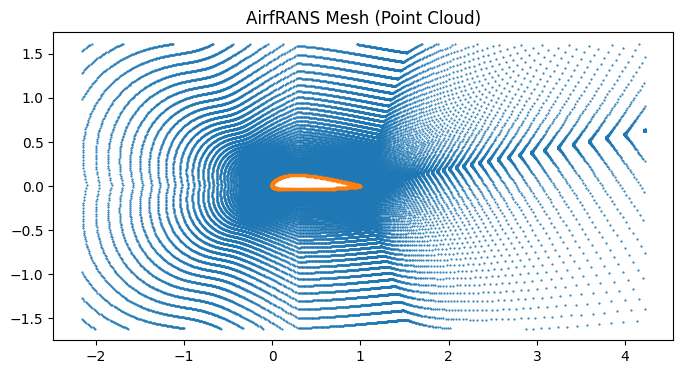

In [27]:
surface = df["surface"]

plt.figure(figsize=(8, 4))
plt.scatter(df["x"][surface == 0], df["y"][surface == 0], s=0.3, label="Flow field")
plt.scatter(df["x"][surface == 1], df["y"][surface == 1], s=2, label="Airfoil surface")
plt.axis("equal")
plt.title("AirfRANS Mesh (Point Cloud)")
plt.show()

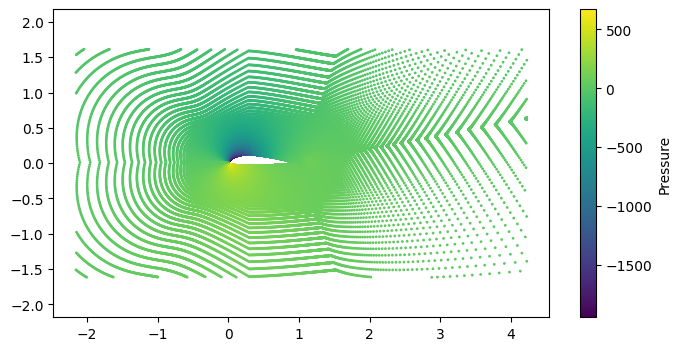

In [11]:
# Visualise the mesh

plt.figure(figsize=(8,4))
plt.scatter(
    df["x"],
    df["y"],
    c=df["pressure"],
    s=1
)

plt.colorbar(label="Pressure")
plt.axis("equal")
plt.show()

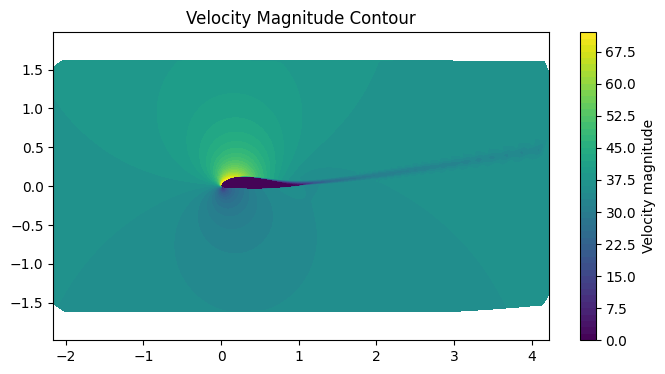

In [23]:
df["velocity"] = np.sqrt(df["vx"]**2 + df["vy"]**2)

plt.figure(figsize=(8,4))
plt.tricontourf(
    df["x"],
    df["y"],
    df["velocity"],
    levels=50, 
    cmap="viridis"

)

plt.colorbar(label="Velocity magnitude")
plt.axis("equal")
plt.title("Velocity Magnitude Contour")
plt.show()

In [31]:
x = df["x"]
y = df["y"]
vx = df["vx"]
vy = df["vy"]

xi = np.linspace(df["x"].min(), df["x"].max(), 200)
yi = np.linspace(df["y"].min(), df["y"].max(), 200)

X, Y = np.meshgrid(xi, yi)

# interpolate velocity onto grid
VX = griddata((x, y), vx, (X, Y), method="linear")
VY = griddata((x, y), vy, (X, Y), method="linear")

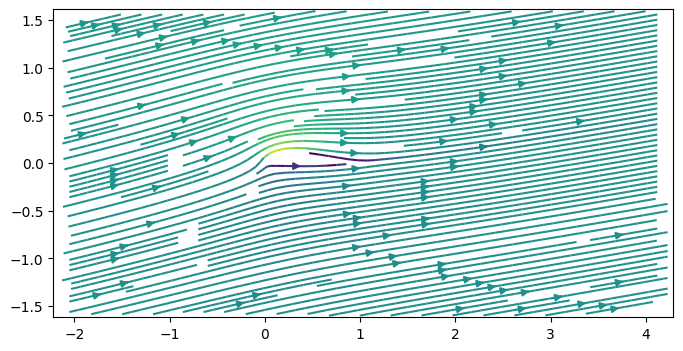

In [35]:
plt.figure(figsize = (8,4))

V = np.sqrt(VX**2 + VY**2)

plt.streamplot(
    X, Y,
    VX, VY,
    color=V,
    cmap="viridis",
    density=2
)

# plt.scatter(x, y, s=0.1, color="black", alpha=0.2)

plt.axis("equal")
plt.show()